# Creating a baseline using a linear model 

The goal of this notebook is to establish whether traditional ML models with scikit-learn can locate splicing junctions. It follows the general workflow: (1) data loading; (2) feature encoding; (3) model fit; (4) model evaluation; (5) hypterparameter tuning. 

The data used is sourced from the UCI *Splice-junction Gene Sequences* set: containing 3,190 windows of 60 DNA bases taken from primate genes. Each window is centered on a candidate splice junction and has the labels:

- EI = exon, intron boundary (a donor site)
- IE = intron, exon boundary (an acceptor site)
- N = neither, a random window with no junction

We know what to expect because (almost) every intron starts with **GT** and ends with **AG**. If the model is actually learning then it will be able to identify this pattern. 

In [3]:
import sys
sys.path.insert(0, "../src") # inserting the source script path

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from splice_utils import load_splice, one_hot, feature_names, POSITIONS, BASES

data = load_splice("../data/splice.data")
print(data.shape)
print(data["label"].value_counts())
data.head()


(3190, 3)
label
N     1655
IE     768
EI     767
Name: count, dtype: int64


,label,name,sequence
0,EI,ATRINS-DONOR-521,CCAGCTGCATCACAGGAGGCCAGCGAGCAGGTCTGTTCCAAGGGCC...
1,EI,ATRINS-DONOR-905,AGACCCGCCGGGAGGCGGAGGACCTGCAGGGTGAGCCCCACCGCCC...
2,EI,BABAPOE-DONOR-30,GAGGTGAAGGACGTCCTTCCCCAGGAGCCGGTGAGAAGCGCAGTCG...
3,EI,BABAPOE-DONOR-867,GGGCTGCGTTGCTGGTCACATTCCTGGCAGGTATGGGGCGGGGCTT...
4,EI,BABAPOE-DONOR-2817,GCTCAGCCCCCAGGTCACCCAGGAACTGACGTGAGTGTCCCCATCC...


## Converting DNA bases into numbers

A model cannot take in the string `CCAGCT...` directly. The main workaround to this is one-hot encoding, creating a 4 x 60 dataframe, with four columns (A, C, G, T), with a 1 in the column for the base that is actually there and a 0 elswhere (binary coded). Therefore, one sequence becomes a vector of 60 x 4 = 240 numbers

A handful of positions (60 out of 191,400) use IUPAC ambiguity codes, where `D` means "A, G or T", `N` means "any base", and so on... Instead of discarding that data, we can spread the 1 evenly across the possible bases (a `D` becomes 1/3, 1/3, 1/3 on A, G, T). Below is an example:

In [8]:
demo = one_hot(["ACGTD"])

pd.DataFrame(demo.reshape(5,4), index = list("ACGTD"), columns=BASES) # BASES is simply a dictionary that contains the four base letters.

,A,C,G,T
A,1.000000,0.0,0.000000,0.000000
C,0.000000,1.0,0.000000,0.000000
G,0.000000,0.0,1.000000,0.000000
T,0.000000,0.0,0.000000,1.000000
D,0.333333,0.0,0.333333,0.333333


In [46]:
X = one_hot(data["sequence"])
y = data["label"].values

names = feature_names()

print("X shape:", x.shape)
print("first few feature names:", names[:6], "...", names[116:124])

X shape: (3190, 240)
first few feature names: ['-30:A', '-30:C', '-30:G', '-30:T', '-29:A', '-29:C'] ... ['-1:A', '-1:C', '-1:G', '-1:T', '+1:A', '+1:C', '+1:G', '+1:T']


##  Holding back data to be used as a test set 

We hold back 1/4 of the data to use it as a test set, where the model never sees it during training. In this case, `stratify=y` keeps the EI/IE/N proportions the same in both halves.

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state = 42, stratify = y
)

print(len(X_train), "training sequences,", len(X_test), "test sequences")

2392 training sequences, 798 test sequences


## Logistic regresion

Logistic regression is the natural first classifier for one-hot features, because it learns one weight per (position, base) pair and sums. Be sure to remember this model, because in notebook 2 we'll see that a single artificial neuron holds the same principles. 

Logistic regression test accuracy: 0.939

              precision    recall  f1-score   support

          EI       0.90      0.93      0.92       192
          IE       0.91      0.92      0.91       192
           N       0.97      0.95      0.96       414

    accuracy                           0.94       798
   macro avg       0.93      0.93      0.93       798
weighted avg       0.94      0.94      0.94       798



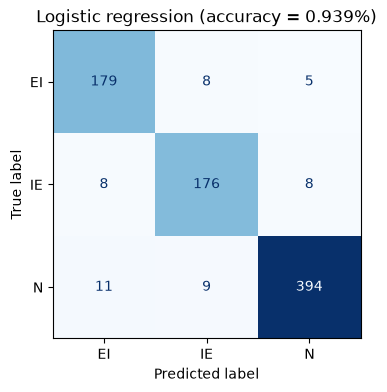

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

logreg = LogisticRegression(max_iter = 2000)

logreg.fit(X_train, y_train)

pred = logreg.predict(X_test)
acc_logreg = accuracy_score(y_test, pred)

print(f"Logistic regression test accuracy: {acc_logreg:.3f}\n") 
#:.3f = to 3 significant figures
print(classification_report(y_test, pred))

# We can create a confusion matrix using this data

fig, ax = plt.subplots(figsize = (4.5, 4)) # create empty xy plane

# Fill with confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, 
                                        pred, 
                                        ax = ax,
                                        colorbar = False,
                                        cmap = "Blues"
                                       )

ax.set_title(f"Logistic regression (accuracy = {acc_logreg:.3f}%)")
plt.savefig("../figures/01_confusion_logreg.png", dpi = 150)

## k-nearest neighbours and choosing k

kNN classifies a sequence by looking at the k most similar training sequences. k is the **hypterparamater**, meaning it is specified. 

sklearn's `GridSearchCV` tries several values, scoring each by cross-validation only on the training set, choosing the best. Once the best fit is identified, you can look at the test dataset.

KNeighborsClassifier(n_neighbors=31)
kNN test accuracy: 0.857


<Axes: xlabel='param_n_neighbors', ylabel='mean_test_score'>

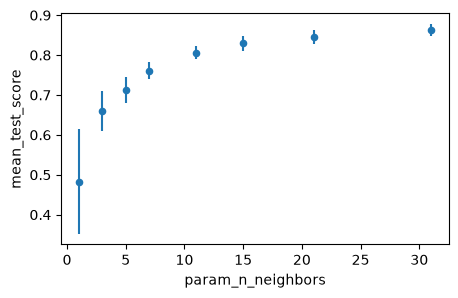

In [67]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

hyperparameters = {"n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}
model = GridSearchCV(KNeighborsClassifier(), hyperparameters)
model.fit(X_train, y_train)

print(model.best_estimator_)
print(f"kNN test accuracy: {model.score(X_test, y_test):.3f}")

cv_results = pd.DataFrame(model.cv_results_)
cv_results.plot.scatter("param_n_neighbors", "mean_test_score", yerr="std_test_score", figsize=(5,3))

## Checking the data through biology

Whilst model accuracy is important, we also want to check if the model has actually learnt correctly. Logistic regression gives one coefficient per (position, base) for each class, so we can lay them out on a 4 x 60 heatmap. A positive weight would indicate that the certain base at the certain position would make the class more likely. 

If the model has learnt the biological rulesets, we would expect: 

- EI (donor): strong positive weights for G at +1 and T at +2, showing the start of the intron
- IE (acceptor): strong positive weights for A at -2 and G at -1, showing the end of the intron. We would also expect to see a preference for C/T further upstream - which is the polypyrimidine tract.

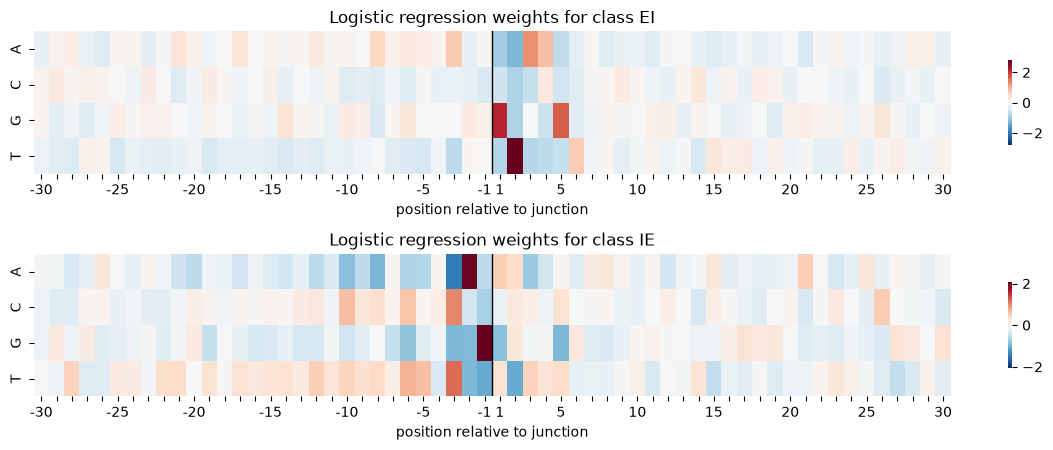

EI → ['+2:T', '+1:G', '+5:G', '+3:A', '+4:A']
IE → ['-1:G', '-2:A', '-3:T', '-3:C', '-6:T']


In [69]:
def weight_heatmap(W, title, ax, vmax=None):
    # W has 240 entries ordered position-major: reshape to (60 positions, 4 bases) then transpose.
    grid = W.reshape(60, 4).T
    vmax = vmax or np.abs(grid).max()
    sns.heatmap(grid, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, ax=ax,
                yticklabels=BASES, xticklabels=[str(p) if p % 5 == 0 or abs(p) == 1 else "" for p in POSITIONS],
                cbar_kws={"shrink": 0.6})
    ax.axvline(30, color="black", lw=1)          # the junction sits between index 29 and 30
    ax.set_title(title)
    ax.set_xlabel("position relative to junction")

fig, axes = plt.subplots(2, 1, figsize=(12, 4.6))
for ax, cls in zip(axes, ["EI", "IE"]):
    W = logreg.coef_[list(logreg.classes_).index(cls)]
    weight_heatmap(W, f"Logistic regression weights for class {cls}", ax)
plt.tight_layout()
plt.savefig("../figures/01_logreg_weights.png", dpi=150)
plt.show()

# The five most positive weights per class, by name
for cls in ["EI", "IE"]:
    W = logreg.coef_[list(logreg.classes_).index(cls)]
    top = np.argsort(W)[::-1][:5]
    print(cls, "→", [names[i] for i in top])

## Summary 

- Standard logistic regression on one-hot encoded bases scores well above 90% on accuracy. The largest weightings are exactly within the GT...AG consensus. This indicates that the model **has** learnt how to identify splice junctions.
- kNN is weaker, because one-hot encoded vectors of two random sequences are unlikely to be close-by in a 240-dimensional space. 

Therefore, logistic regression will act as the baseline. In the next notebook, we will build a single artificial neuron manually, show that it is essentially logistic regression, and then add a hidden layer to see whether a neural network can score higher. 